In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

In [62]:
window_length = 30 # number of time steps in each window
trip_fraction = 0.1 # fraction of windows followed by a trip
rng = np.random.default_rng(1) # random number generator with seed 1
t = np.arange(window_length) # time axis of 0 - 29

print(t)               

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]


Simulate 3 window (30 sensor readings per sensor) types:
- Normal
- Before trip with warning 
- Before trip with no warning

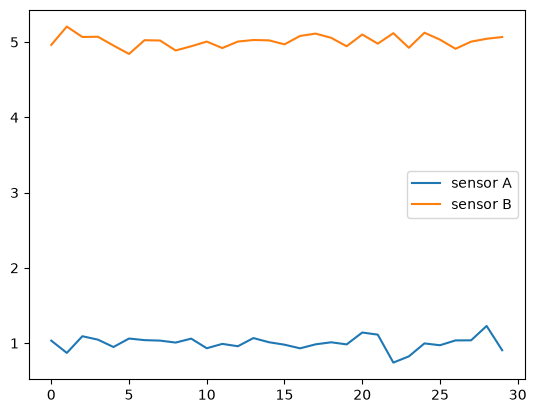

In [63]:
def make_normal_window():
    # baselines, arbitrary units
    slope_a = rng.normal(0, 0.05) # random slow drift for A across window
    slope_b = rng.normal(0, 0.05)     

    # slope grows from nothing to almost full value. rng normal is random jitter at each time step
    sensor_a = 1.0 + slope_a * t / window_length + rng.normal(0, 0.10, window_length)
    sensor_b = 5.0 + slope_b * t / window_length + rng.normal(0, 0.10, window_length)

    return sensor_a, sensor_b

a, b = make_normal_window()
plt.plot(t, a, label="sensor A")
plt.plot(t, b, label="sensor B")
plt.legend()
plt.show()

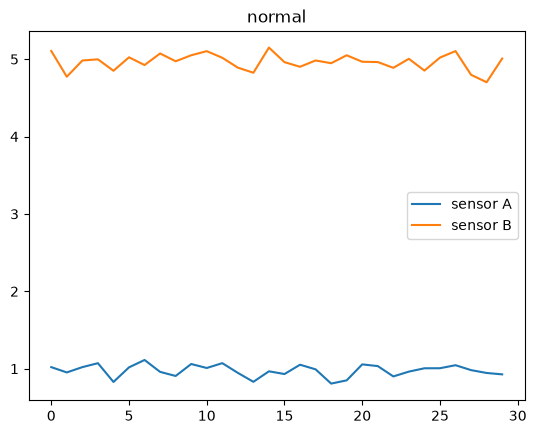

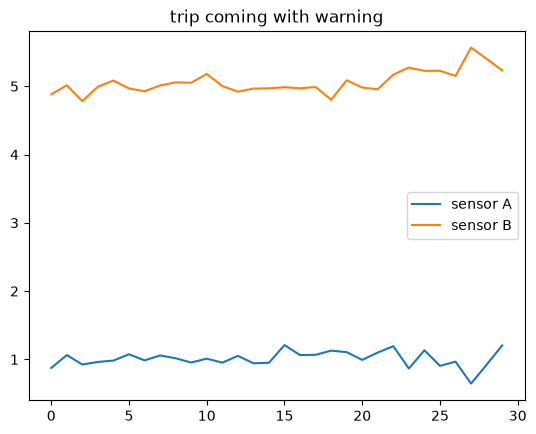

In [64]:
def make_trip_window(warning):
    sensor_a, sensor_b = make_normal_window() # initially a normal window
    if warning: 
        strength = rng.uniform(0.3, 1.0) 
        start = rng.integers(8, 22) # time step of warning start
        ramp = np.clip((t - start) / (window_length - start), 0, None) # 0 before start and increases toward 1

        jitter = rng.normal(0, 1, window_length) * 0.5 * strength * ramp # noise on A
        lean = 0.5 * strength * ramp # drift on B

        sensor_a += jitter
        sensor_b += lean

    return sensor_a, sensor_b

normal_a, normal_b = make_normal_window()
plt.plot(t, normal_a, label="sensor A")
plt.plot(t, normal_b, label="sensor B")
plt.title("normal")
plt.legend()
plt.show()

warn_a, warn_b = make_trip_window(True)
plt.plot(t, warn_a, label="sensor A")
plt.plot(t, warn_b, label="sensor B")
plt.title("trip coming with warning")
plt.legend()
plt.show()

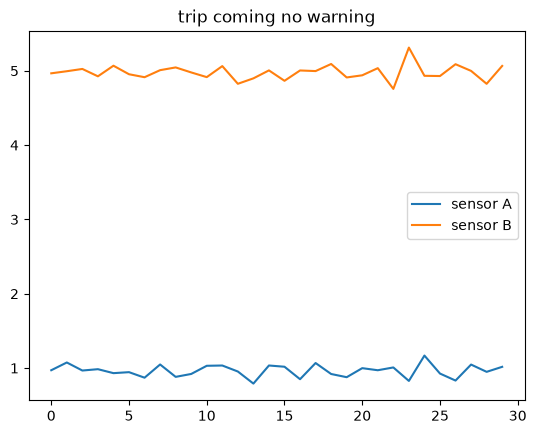

In [65]:
silent_a, silent_b = make_trip_window(False)
plt.plot(t, silent_a, label="sensor A")
plt.plot(t, silent_b, label="sensor B")
plt.title("trip coming no warning")
plt.legend()
plt.show()

Turn window into numbers (features) that can be passed into a model

Each window with 30 numbers per sensor is summarized into mean, std, slope

In [66]:
def summarize_window(sensor_a, sensor_b):
    slope_a = np.polyfit(t, sensor_a, 1)[0] # best fit slope over window 
    slope_b = np.polyfit(t, sensor_b, 1)[0]

    return [sensor_a.mean(), sensor_a.std(), slope_a, sensor_b.mean(), sensor_b.std(), slope_b]

example_a, example_b = make_normal_window()
print(summarize_window(example_a, example_b))

example_a, example_b = make_trip_window(True)
print(summarize_window(example_a, example_b))

[np.float64(1.0280559174922086), np.float64(0.07947516983115158), np.float64(0.003873694690878753), np.float64(4.965298656956665), np.float64(0.08834374526907814), np.float64(0.001608355835564819)]
[np.float64(1.0231913645498625), np.float64(0.14508003575410686), np.float64(0.00474591197151482), np.float64(5.095537543193861), np.float64(0.1628585231295506), np.float64(0.013919598979218172)]


Turn into a dataset 
- 3000 windows as examples for the rows, each with 6 features
- Final column is whether trip occurred (weighted random to decide if there is a trip, another random to decide if there is a warning)

In [67]:
n_windows = 3000          
warning_fraction = 0.8 # fraction of trips with a warning

features = ["a_mean", "a_std", "a_slope", "b_mean", "b_std", "b_slope"]
rows = []              
labels = [] # 1 if trip, 0 if no trip

for i in range(n_windows):
    trip = rng.random() < trip_fraction # trip_fraction true 10% of the time
    if trip:
        warn = rng.random() < warning_fraction
        sensor_a, sensor_b = make_trip_window(warn)
    else:
        sensor_a, sensor_b = make_normal_window()

    rows.append(summarize_window(sensor_a, sensor_b))
    labels.append(int(trip))

df = pd.DataFrame(rows, columns=features)
df["trip"] = labels
df.head()

,a_mean,a_std,a_slope,b_mean,b_std,b_slope,trip
0,1.045304,0.090485,0.003151,5.011999,0.088374,-0.000078,0
1,0.994413,0.120346,-0.000833,4.981839,0.091808,-0.003137,0
2,0.991510,0.112978,-0.003132,5.033030,0.107009,0.003470,0
3,0.998241,0.105798,-0.004878,4.975366,0.109768,0.002530,0
4,0.987693,0.121826,0.003198,4.930136,0.105782,-0.006806,0


In [68]:
print(df.shape)
print(df["trip"].mean())
print(df.groupby("trip").mean())

(3000, 7)
0.088
        a_mean     a_std   a_slope    b_mean     b_std   b_slope
trip                                                            
0     1.000224  0.098887 -0.000068  5.000325  0.098203 -0.000011
1     0.996774  0.147002 -0.000357  5.062630  0.131333  0.008274


Split data into train and test sets to set aside testing data

In [69]:
X = df[features]
y = df["trip"] # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(2400, 6) (600, 6)
0.08791666666666667 0.08833333333333333


Create a baseline model

In [70]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

print(baseline.score(X_test, y_test)) # accuracy
print(baseline.predict(X_test).sum()) # total trips predicted

0.9116666666666666
0


Fit one logistic regression (no tuning)

In [71]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

# probability of a trip for the first 10 training windows
print(model.predict_proba(X_train)[:10, 1].round(3))
# target labels
print(y_train.values[:10])

# weights of features
weights = pd.Series(model[-1].coef_[0], index=features)
print(weights.round(2))

[0.033 0.023 0.153 0.012 0.009 0.009 0.032 0.042 0.011 0.007]
[0 0 0 0 0 0 0 0 0 0]
a_mean    -0.21
a_std      1.19
a_slope    0.12
b_mean     0.15
b_std      0.37
b_slope    1.56
dtype: float64


Tune C using cross validation

In [72]:
param_grid = {"logisticregression__C": np.logspace(-3, 2, 12)} #0.001 to 100

grid = GridSearchCV(model, param_grid, cv=5, scoring="average_precision")
grid.fit(X_train, y_train)

print(np.logspace(-3, 2, 12))
print(grid.best_params_)
print(grid.best_score_)

[1.00000000e-03 2.84803587e-03 8.11130831e-03 2.31012970e-02
 6.57933225e-02 1.87381742e-01 5.33669923e-01 1.51991108e+00
 4.32876128e+00 1.23284674e+01 3.51119173e+01 1.00000000e+02]
{'logisticregression__C': np.float64(0.1873817422860383)}
0.8335640752531551


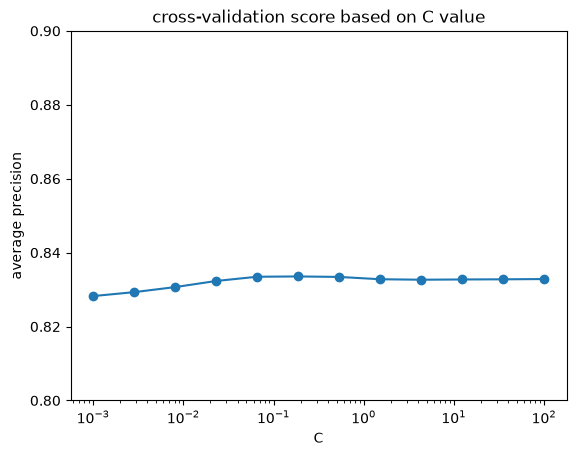

In [73]:
results = pd.DataFrame(grid.cv_results_)

c_values = results["param_logisticregression__C"].astype(float)
scores = results["mean_test_score"]

plt.plot(c_values, scores, marker="o")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("average precision")
plt.title("cross-validation score based on C value")
plt.ylim(0.8, 0.9)
plt.show()

Differences this small are likely noise from fold to fold

Choose highest scoring C but exact C should not matter much. Then explicit retraining on on training data.

In [74]:
best_c = grid.best_params_["logisticregression__C"]
model = make_pipeline(StandardScaler(), LogisticRegression(C=best_c, max_iter=1000))
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['a_mean','a_std','a_slope','b_mean','b_std','b_slope']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Choose best threshold using F1 score to balance false alarms and missed trips. Don't know real tradeoff so equal.

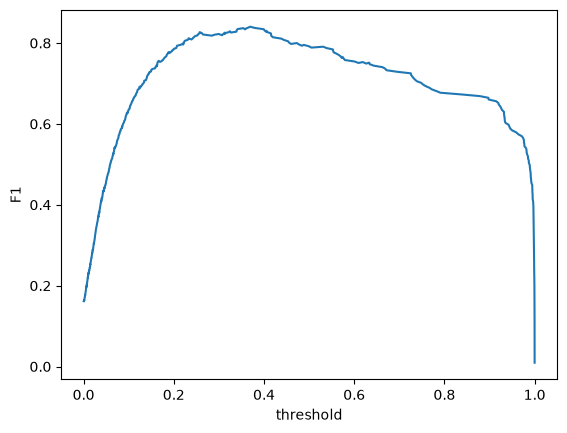

0.3691545798817565 0.8404255319148937


In [79]:
train_probs = cross_val_predict(model, X_train, y_train, cv=5, method="predict_proba")[:, 1]

thresholds = np.unique(train_probs)
f1_scores = []

for threshold in thresholds:
    pred = (train_probs >= threshold).astype(int)
    f1_scores.append(f1_score(y_train, pred, zero_division=0))

plt.plot(thresholds, f1_scores)
plt.xlabel("threshold")
plt.ylabel("F1")
plt.show()

best_threshold = thresholds[np.argmax(f1_scores)]
print(best_threshold, max(f1_scores))

In [81]:
table_thresholds = [0.5, 0.4, best_threshold, 0.3, 0.2, 0.1, 0]
rows = []

for tt in table_thresholds:
    pred = (train_probs >= tt).astype(int)
    cm = confusion_matrix(y_train, pred)
    rows.append([tt, cm[1, 1], cm[1, 0], cm[0, 1], precision_score(y_train, pred), recall_score(y_train, pred)])

threshold_table = pd.DataFrame(rows, columns=["threshold", "caught", "missed", "false_alarms", "precision", "recall"])
threshold_table.round(3)

,threshold,caught,missed,false_alarms,precision,recall
0,0.500,140,71,4,0.972,0.664
1,0.400,155,56,7,0.957,0.735
2,0.369,158,53,7,0.958,0.749
3,0.300,161,50,21,0.885,0.763
4,0.200,167,44,47,0.780,0.791
5,0.100,171,40,155,0.525,0.810
6,0.000,211,0,2189,0.088,1.000


Final test set evaluation

In [82]:
final_probs = model.predict_proba(X_test)[:, 1]
final_pred = (final_probs >= best_threshold).astype(int)

print(confusion_matrix(y_test, final_pred))
print("precision:", precision_score(y_test, final_pred))
print("recall:", recall_score(y_test, final_pred))
print("f1:", f1_score(y_test, final_pred))

[[544   3]
 [ 13  40]]
precision: 0.9302325581395349
recall: 0.7547169811320755
f1: 0.8333333333333334


Final Stats:

Caught 40 out of 53 trips

3 false alarms out of 547 normal windows

ROC curve and auc score

AUC: 0.8887585802490428


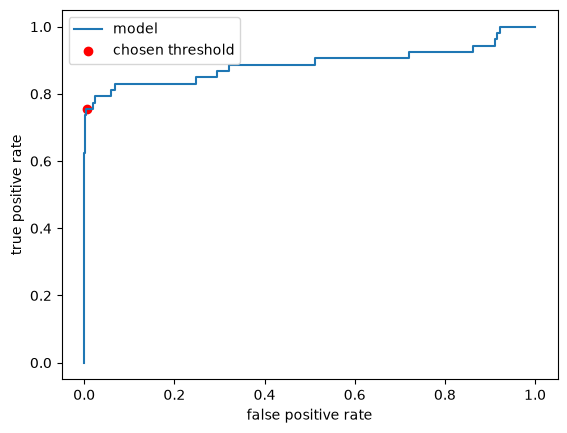

In [86]:
fpr, tpr, roc_thresholds = roc_curve(y_test, final_probs)
print("AUC:", roc_auc_score(y_test, final_probs))

# where chosen threshold sits on curve
cm = confusion_matrix(y_test, final_pred)
chosen_fpr = cm[0, 1] / (cm[0, 0] + cm[0, 1]) # false alarms / normal windows
chosen_tpr = cm[1, 1] / (cm[1, 0] + cm[1, 1]) # caught trips / trips

plt.plot(fpr, tpr, label="model")
plt.scatter(chosen_fpr, chosen_tpr, color="red", label="chosen threshold")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.legend()
plt.show()

Add precision recall curve - useful when positive class is rare

How trustworthy the model's positive predictions are versus how many real positives caught.

average precision: 0.8258550006047466


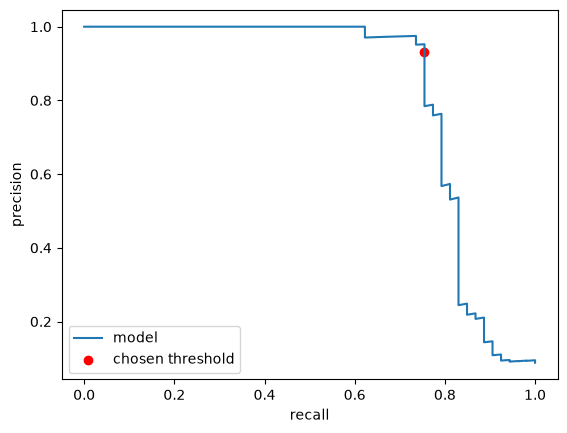

In [89]:
precision, recall, pr_thresholds = precision_recall_curve(y_test, final_probs)
print("average precision:", average_precision_score(y_test, final_probs))

chosen_precision = precision_score(y_test, final_pred)
chosen_recall = recall_score(y_test, final_pred)

plt.plot(recall, precision, label="model")
plt.scatter(chosen_recall, chosen_precision, color="red", label="chosen threshold")
plt.xlabel("recall")
plt.ylabel("precision")
plt.legend()
plt.show()